# 02 · Statistical analysis

**"AI Effect" priming experiment** · Bora Şenoğlu

The question behind the experiment: the Google Effect says people remember less when they know the information is one search away (Sparrow et al., 2011). These days we delegate whole tasks to AI, not just facts. So does simply being reminded of AI make people put in less cognitive effort?

If it does, participants primed with AI should, compared to the neutral group,

- give more wrong answers (guessing instead of thinking),
- give up faster (less time before choosing "I don't know"),
- and maybe respond faster in general.

One thing up front. Nothing here was preregistered and the sample is small, so everything in this notebook is **exploratory**. I treat the p-values as a rough guide to what might be worth a proper study, not as proof of anything.

*A note on how this was made: the code here too was written with the help of AI assistants and then reviewed and reworked. The README explains exactly where AI was used.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import FTestAnovaPower
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

# works whether Jupyter was started in the repository root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'figures'

CONDITION_ORDER = ['Neutral', 'Google control', 'AI semantic', 'AI brand']

In [2]:
everyone = pd.read_csv(DATA / 'participants_clean.csv', index_col='participant')

# main sample: without the two participants who tapped through the cover task (see notebook 01)
df = everyone[~everyone['flag_clickthrough']].copy()

print('All participants:', len(everyone))
print('Main sample:     ', len(df))
df['condition'].value_counts().loc[CONDITION_ORDER]

All participants: 39
Main sample:      37


condition
Neutral            9
Google control    11
AI semantic        9
AI brand           8
Name: count, dtype: int64

## 1. Who took part

In [3]:
for column in ['gender', 'age', 'education', 'english', 'ai_use']:
    print(df[column].value_counts().to_string(), '\n')

gender
Male                 17
Female               17
Non-binary            2
Prefer not to say     1 

age
18-24                27
25-34                 8
Prefer not to say     2 

education
Bachelor             27
High school           4
Master                3
Prefer not to say     3 

english
C1-C2     24
Native     5
B1-B2      5
A1-A2      3 

ai_use
A few times a week     15
Daily                  13
Rarely or Never         6
A few times a month     3 



Mostly bachelor students between 18 and 24, which is what you get with snowball sampling from a university. Almost everyone uses AI tools at least a few times a week.

## 2. Did random assignment give comparable groups?

Random assignment is supposed to make the groups similar on everything except the prime. With about nine people per group that can easily fail just by chance, so I check the two background variables that could plausibly affect the task: English proficiency (the questions were in English) and how often people use AI.

In [4]:
english_levels = ['A1-A2', 'B1-B2', 'C1-C2', 'Native']
ai_levels = ['Rarely or Never', 'A few times a month', 'A few times a week', 'Daily']

display(pd.crosstab(df['condition'], df['english']).loc[CONDITION_ORDER, english_levels])
display(pd.crosstab(df['condition'], df['ai_use']).loc[CONDITION_ORDER, ai_levels])

english,A1-A2,B1-B2,C1-C2,Native
condition,,,,
Neutral,0,1,8,0
Google control,1,1,5,4
AI semantic,0,1,8,0
AI brand,2,2,3,1


ai_use,Rarely or Never,A few times a month,A few times a week,Daily
condition,,,,
Neutral,3,0,2,4
Google control,2,1,5,3
AI semantic,0,2,5,2
AI brand,1,0,3,4


AI use looks reasonably spread out. English proficiency does not. Half of the AI brand group (4 of 8) rated their English below C1, against one or two people in each of the other groups. I come back to this in section 8, because it turns out to matter.

## 3. Look at the data before testing anything

With groups this small I want to see every participant, not just a bar with an error line. Each dot is one person. The black diamond is the group mean with a 95% confidence interval.

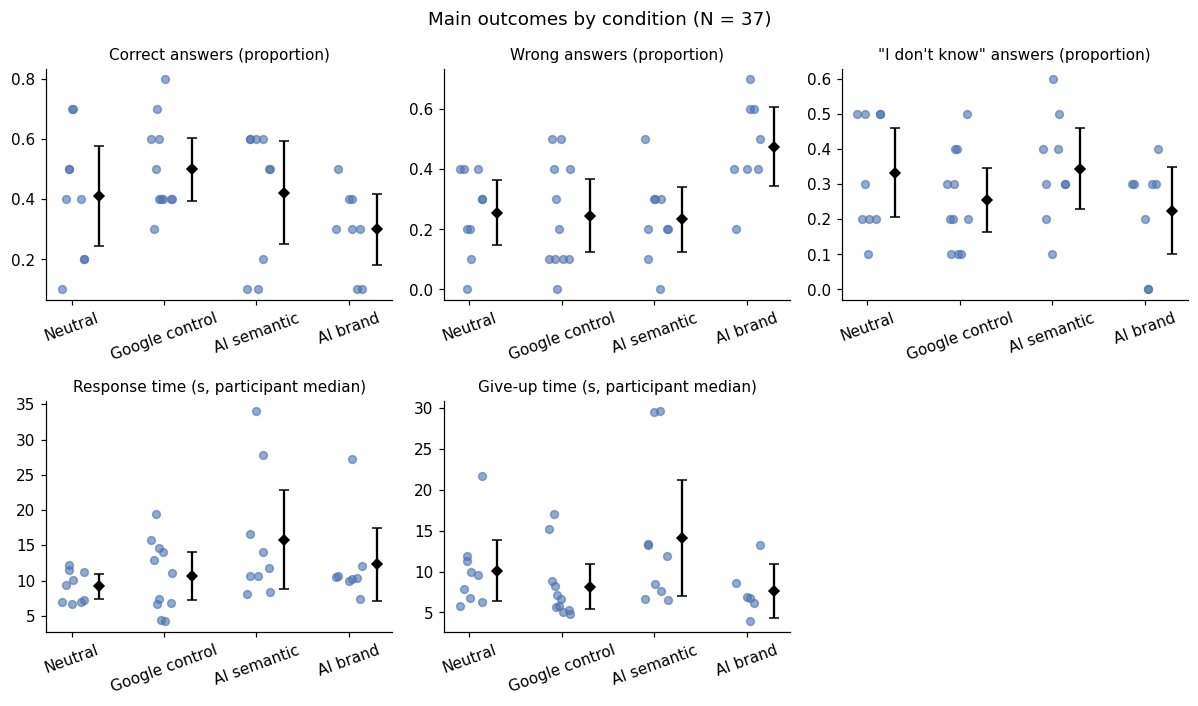

In [5]:
main_outcomes = {
    'prop_correct': 'Correct answers (proportion)',
    'prop_wrong': 'Wrong answers (proportion)',
    'prop_idk': '"I don\'t know" answers (proportion)',
    'median_rt_s': 'Response time (s, participant median)',
    'giveup_median_s': 'Give-up time (s, participant median)',
}


def strip_plot(ax, data, outcome, title):
    """One dot per participant, plus the group mean with a 95% confidence interval."""
    rng = np.random.default_rng(1)
    for x, condition in enumerate(CONDITION_ORDER):
        values = data.loc[data['condition'] == condition, outcome].dropna()
        jitter = rng.uniform(-0.15, 0.15, len(values))
        ax.scatter(x + jitter, values, color='#4c72b0', alpha=0.6, s=26)
        ci = stats.t.ppf(0.975, len(values) - 1) * values.sem()
        ax.errorbar(x + 0.3, values.mean(), yerr=ci, fmt='D', color='black',
                    capsize=3, markersize=5)
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=20)
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, (outcome, title) in zip(axes.flat, main_outcomes.items()):
    strip_plot(ax, df, outcome, title)
axes.flat[-1].axis('off')

fig.suptitle('Main outcomes by condition (N = {})'.format(len(df)))
fig.tight_layout()
fig.savefig(FIGURES / '03_outcomes_by_condition.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
summary = df.groupby('condition')[list(main_outcomes)].agg(['mean', 'std']).loc[CONDITION_ORDER]
summary.insert(0, ('participants', 'n'), df.groupby('condition').size())
summary.round(2)

participants prop_correct       prop_wrong       prop_idk       median_rt_s       giveup_median_s      
                          n         mean   std       mean   std     mean   std        mean   std            mean   std
condition                                                                                                             
Neutral                   9         0.41  0.21       0.26  0.14     0.33  0.17        9.15  2.22           10.12  4.84
Google control           11         0.50  0.15       0.25  0.18     0.25  0.14       10.66  5.10            8.16  4.16
AI semantic               9         0.42  0.22       0.23  0.14     0.34  0.15       15.78  9.11           14.10  9.15
AI brand                  8         0.30  0.14       0.48  0.16     0.22  0.15       12.28  6.20            7.60  3.16

The AI brand group stands out on wrong answers: 48% on average, against 23 to 26% in the other three groups. Their share of correct answers is also the lowest (30%). For the two time measures the AI semantic group is the slow one, but the plot shows that this is mostly two participants who took a lot longer than everyone else.

## 4. One-way ANOVAs, with the checks

- **eta squared**, the share of variance explained by condition, so there is an effect size next to each p-value;
- **Shapiro-Wilk** on the residuals and **Levene's test**, to check the ANOVA assumptions of normality and equal variances (a p below .05 means the assumption is doubtful);
- **Kruskal-Wallis**, a rank-based test that does not need those assumptions. If ANOVA and Kruskal-Wallis disagree, I trust the result less.

I also apply a **Holm correction** across the five outcomes. Testing five things gives five chances of a false positive, and Holm adjusts the p-values for that.

In [7]:
def one_way_anova(data, outcome):
    """One-way ANOVA of an outcome by condition, with effect size and assumption checks."""
    d = data.dropna(subset=[outcome])
    model = ols('{} ~ C(condition)'.format(outcome), data=d).fit()
    table = sm.stats.anova_lm(model, typ=2)

    ss_condition = table.loc['C(condition)', 'sum_sq']
    ss_residual = table.loc['Residual', 'sum_sq']
    groups = [group[outcome] for _, group in d.groupby('condition')]

    return {
        'outcome': outcome,
        'N': len(d),
        'df': '{:.0f}, {:.0f}'.format(table.loc['C(condition)', 'df'], table.loc['Residual', 'df']),
        'F': table.loc['C(condition)', 'F'],
        'p': table.loc['C(condition)', 'PR(>F)'],
        'eta_sq': ss_condition / (ss_condition + ss_residual),
        'shapiro_p': stats.shapiro(model.resid)[1],
        'levene_p': stats.levene(*groups)[1],
        'kruskal_p': stats.kruskal(*groups)[1],
    }


results = pd.DataFrame([one_way_anova(df, outcome) for outcome in main_outcomes]).set_index('outcome')
results.insert(4, 'p_holm', multipletests(results['p'], method='holm')[1])
results.round(3)

,N,df,F,p,p_holm,eta_sq,shapiro_p,levene_p,kruskal_p
outcome,,,,,,,,,
prop_correct,37,"3, 33",1.786,0.169,0.464,0.140,0.122,0.629,0.161
prop_wrong,37,"3, 33",4.462,0.010,0.049,0.289,0.282,0.595,0.026
prop_idk,37,"3, 33",1.347,0.276,0.464,0.109,0.088,0.807,0.370
median_rt_s,37,"3, 33",1.979,0.136,0.464,0.152,0.001,0.300,0.204
giveup_median_s,35,"3, 31",2.134,0.116,0.464,0.171,0.000,0.225,0.150


Only wrong answers show an effect of condition: F(3, 33) = 4.46, p = .010, eta squared = .29. The assumption checks are fine for this outcome, Kruskal-Wallis agrees (p = .026), and it survives the Holm correction. Just: the corrected p is .049, and I would not bet much on a p-value of .049.

Nothing else is significant. For the two time measures Shapiro-Wilk says the residuals are not normal (those few slow participants again), so there the Kruskal-Wallis column is the one to look at. It says the same thing: no clear difference between the groups.

One more thing to keep in mind: correct, wrong and "I don't know" always add up to 100%, so these are not three independent tests. If one goes up, another has to come down.

## 5. Post hoc: which groups differ on wrong answers?

In [ ]:
tukey_wrong = pairwise_tukeyhsd(endog=df['prop_wrong'], groups=df['condition'], alpha=0.05)
tukey_wrong.summary()

        Multiple Comparison of Means - Tukey HSD, FWER=0.05         
    group1         group2     meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------
      AI brand    AI semantic  -0.2417 0.0175 -0.4494 -0.0339   True
      AI brand Google control  -0.2295 0.0184 -0.4282 -0.0309   True
      AI brand        Neutral  -0.2194 0.0352 -0.4272 -0.0117   True
   AI semantic Google control   0.0121 0.9982 -0.1801  0.2043  False
   AI semantic        Neutral   0.0222 0.9906 -0.1793  0.2238  False
Google control        Neutral   0.0101  0.999 -0.1821  0.2023  False
--------------------------------------------------------------------


The AI brand group gave more wrong answers than each of the other three groups (adjusted p between .018 and .035), and those three do not differ from each other at all.

AI brand against Neutral is the comparison we were hoping for. But the AI semantic group, which was also primed with AI, behaves just like the neutral group. So if this is a priming effect, it is an effect of AI *logos* and not of the idea of AI in general. Or it is not a priming effect at all, which is what sections 8 and 9 look into.

## 6. Give-up time: the finding that does not hold up

In [9]:
giveup = pd.DataFrame([one_way_anova(df, 'giveup_mean_s'),
                       one_way_anova(df, 'giveup_median_s')]).set_index('outcome')
display(giveup.round(3))

display(df.groupby('condition')[['giveup_mean_s', 'giveup_median_s']]
          .agg(['mean', 'std']).loc[CONDITION_ORDER].round(2))

with_giveup = df.dropna(subset=['giveup_mean_s'])
print(pairwise_tukeyhsd(with_giveup['giveup_mean_s'], with_giveup['condition']).summary())

,N,df,F,p,eta_sq,shapiro_p,levene_p,kruskal_p
outcome,,,,,,,,
giveup_mean_s,35,"3, 31",3.556,0.025,0.256,0.055,0.031,0.125
giveup_median_s,35,"3, 31",2.134,0.116,0.171,0.000,0.225,0.150


giveup_mean_s        giveup_median_s      
                        mean    std            mean   std
condition                                                
Neutral                10.36   3.19           10.12  4.84
Google control         10.11   5.00            8.16  4.16
AI semantic            18.00  11.19           14.10  9.15
AI brand                8.18   2.97            7.60  3.16

         Multiple Comparison of Means - Tukey HSD, FWER=0.05         
    group1         group2     meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------
      AI brand    AI semantic   9.8141 0.0417   0.2809 19.3474   True
      AI brand Google control     1.93 0.9401    -7.25 11.1101  False
      AI brand        Neutral    2.181 0.9246  -7.3523 11.7142  False
   AI semantic Google control  -7.8841   0.06 -16.0141  0.2459  False
   AI semantic        Neutral  -7.6332 0.0923   -16.16  0.8936  False
Google control        Neutral   0.2509 0.9998  -7.8791  8.3809  False
---------------------------------------------------------------------


With mean give-up times the ANOVA is significant (p = .025). But three things make me not trust it:

1. Levene's test fails (p = .031). The AI semantic group has a standard deviation of 11 seconds against 3 seconds in Neutral and AI brand, and both ANOVA and Tukey assume the groups have a similar spread.
2. Kruskal-Wallis is not significant (p = .125), and neither is the ANOVA on median give-up times (p = .116).
3. The post hoc test shows what is going on. The only significant pair is AI semantic against AI brand. AI brand against Neutral is nowhere near (8.2 against 10.4 seconds, p = .92).

The AI brand group did not give up meaningfully faster than the neutral group. The effect comes from a couple of people in the AI semantic group who waited very long before giving up.

Give-up time is also based on very few trials per person: 15 of the 37 participants chose "I don't know" twice or less.

## 7. Where do the extra wrong answers come from?

A participant can avoid a wrong answer in two ways: by knowing the answer, or by choosing "I don't know". So "more wrong answers" could mean the AI brand group knew less, or that they guessed where others gave up. Splitting the answers by question type helps to tell these apart.

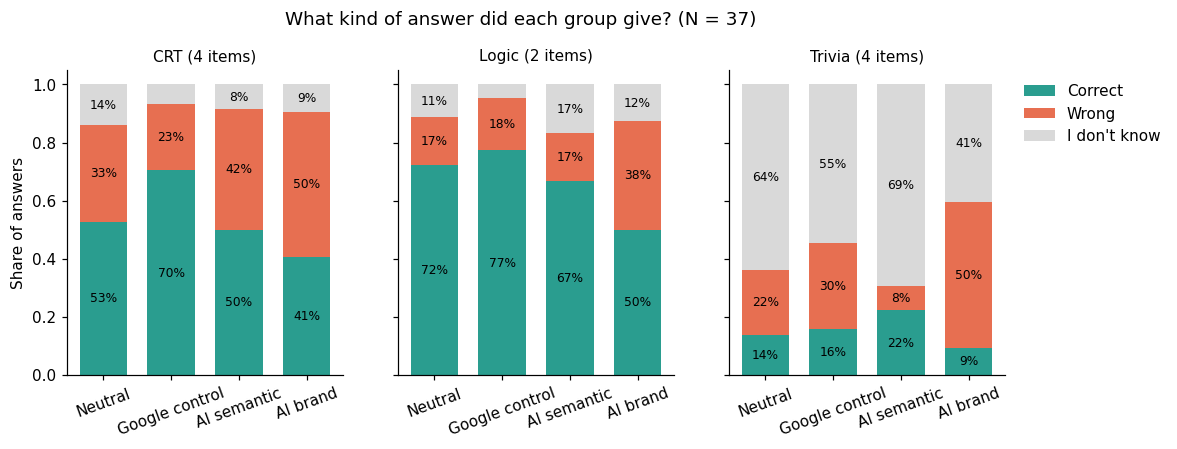

In [10]:
answer_types = {'correct': ('Correct', '#2a9d8f'),
                'wrong': ('Wrong', '#e76f51'),
                'idk': ("I don't know", '#d9d9d9')}
question_types = {'crt': 'CRT (4 items)', 'logic': 'Logic (2 items)', 'trivia': 'Trivia (4 items)'}

group_means = df.groupby('condition').mean(numeric_only=True).loc[CONDITION_ORDER]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (qtype, title) in zip(axes, question_types.items()):
    bottom = np.zeros(len(CONDITION_ORDER))
    for answer, (label, color) in answer_types.items():
        heights = group_means['{}_{}'.format(qtype, answer)].values
        ax.bar(CONDITION_ORDER, heights, bottom=bottom, color=color, label=label, width=0.7)
        for x, (h, b) in enumerate(zip(heights, bottom)):
            if h >= 0.08:
                ax.text(x, b + h / 2, '{:.0%}'.format(h), ha='center', va='center', fontsize=8)
        bottom += heights
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=20)
axes[0].set_ylabel('Share of answers')
axes[2].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

fig.suptitle('What kind of answer did each group give? (N = {})'.format(len(df)), y=1.03)
fig.savefig(FIGURES / '04_answers_by_question_type.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# the same ANOVA function on the finer-grained measures (exploratory, no correction applied)
exploratory_outcomes = ['trivia_correct', 'trivia_wrong', 'trivia_idk',
                        'crt_lure_rate', 'acc_when_attempted']

display(group_means[exploratory_outcomes].round(2))
pd.DataFrame([one_way_anova(df, outcome) for outcome in exploratory_outcomes]).set_index('outcome').round(3)

,trivia_correct,trivia_wrong,trivia_idk,crt_lure_rate,acc_when_attempted
condition,,,,,
Neutral,0.14,0.22,0.64,0.28,0.60
Google control,0.16,0.30,0.55,0.20,0.68
AI semantic,0.22,0.08,0.69,0.39,0.61
AI brand,0.09,0.50,0.41,0.44,0.39


,N,df,F,p,eta_sq,shapiro_p,levene_p,kruskal_p
outcome,,,,,,,,
trivia_correct,37,"3, 33",0.547,0.653,0.047,0.000,0.729,0.748
trivia_wrong,37,"3, 33",4.408,0.010,0.286,0.213,0.019,0.026
trivia_idk,37,"3, 33",2.008,0.132,0.154,0.026,0.879,0.180
crt_lure_rate,37,"3, 33",1.966,0.138,0.152,0.060,0.807,0.148
acc_when_attempted,37,"3, 33",2.606,0.068,0.192,0.522,0.737,0.074


The extra wrong answers are mostly a trivia thing. The trivia questions were designed to be too hard to know, and on those the AI brand group answered wrong 50% of the time, against 8 to 30% in the other groups. They chose "I don't know" less often (41% against 55 to 69%), and their share of correct trivia answers was not higher (9%). So they did not know more. They guessed more, and the guesses were mostly wrong.

On the CRT, the AI brand group gave the intuitive lure answer most often (44%), but the AI semantic group is right behind (39%) and the difference between groups is not significant.

All of this is exploratory.

## 8. The catch: English proficiency

Back to the imbalance from section 2. If people with lower English proficiency give more wrong answers in general, and half of the AI brand group has lower proficiency, then the "priming effect" could simply be a language effect.

In [12]:
display(df.groupby('english_high')[['prop_correct', 'prop_wrong', 'prop_idk']]
          .agg(['mean', 'count']).round(2))

# condition effect on wrong answers, with English proficiency in the model
model_english = ols('prop_wrong ~ C(condition) + C(english_high)', data=df).fit()
sm.stats.anova_lm(model_english, typ=2).round(4)

prop_correct       prop_wrong       prop_idk      
                     mean count       mean count     mean count
english_high                                                   
False                0.26     8       0.45     8     0.29     8
True                 0.46    29       0.25    29     0.29    29

,sum_sq,df,F,PR(>F)
C(condition),0.1837,3.0,2.6893,0.0628
C(english_high),0.0958,1.0,4.2071,0.0485
Residual,0.7287,32.0,NaN,NaN


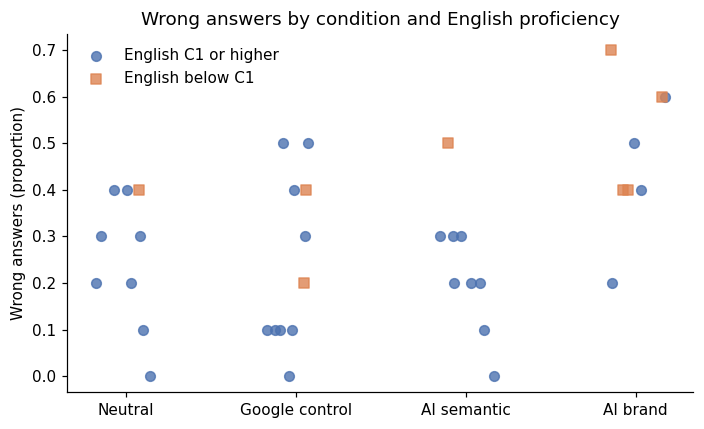

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4))
rng = np.random.default_rng(3)

styles = {True: ('C1 or higher', '#4c72b0', 'o'), False: ('below C1', '#dd8452', 's')}
for is_high, (label, color, marker) in styles.items():
    subset = df[df['english_high'] == is_high]
    x = subset['condition'].map({c: i for i, c in enumerate(CONDITION_ORDER)})
    ax.scatter(x + rng.uniform(-0.18, 0.18, len(subset)), subset['prop_wrong'],
               color=color, marker=marker, s=40, alpha=0.8, label='English ' + label)

ax.set_xticks(range(len(CONDITION_ORDER)))
ax.set_xticklabels(CONDITION_ORDER)
ax.set_ylabel('Wrong answers (proportion)')
ax.set_title('Wrong answers by condition and English proficiency')
ax.legend(frameon=False, loc='upper left')

fig.tight_layout()
fig.savefig(FIGURES / '05_wrong_answers_english.png', dpi=150, bbox_inches='tight')
plt.show()

This is the part I find most important. Participants with English below C1 gave wrong answers 45% of the time, the others 25%. And four of those eight participants ended up in the AI brand group.

With English proficiency in the model, the effect of condition goes from p = .010 to p = .063. It does not vanish. In the figure, the four high-proficiency participants in the AI brand group also sit higher than most high-proficiency participants elsewhere. But four people is four people. With this sample I cannot separate "was primed with AI logos" from "happened to land in the group with weaker English", so I think the fair conclusion is that the wrong-answer effect is **confounded**.


### AI use frequency and gender

I was curious about how AI use frequency and gender correlates with the responses given.

In [14]:
for outcome in ['prop_correct', 'prop_wrong', 'prop_idk', 'crt_lure_rate']:
    rho, p = stats.spearmanr(df['ai_use_num'], df[outcome])
    print('AI use frequency vs {:<14} Spearman rho = {:+.2f}, p = {:.3f}'.format(outcome, rho, p))

print()
women = df[df['gender'] == 'Female']
men = df[df['gender'] == 'Male']
for outcome in ['prop_correct', 'prop_wrong']:
    t, p = stats.ttest_ind(women[outcome], men[outcome], equal_var=False)
    print('Gender, {:<13} women {:.2f} vs men {:.2f}, Welch t = {:+.2f}, p = {:.3f}'.format(
        outcome, women[outcome].mean(), men[outcome].mean(), t, p))

AI use frequency vs prop_correct   Spearman rho = -0.32, p = 0.055
AI use frequency vs prop_wrong     Spearman rho = +0.38, p = 0.022
AI use frequency vs prop_idk       Spearman rho = -0.06, p = 0.719
AI use frequency vs crt_lure_rate  Spearman rho = +0.35, p = 0.033

Gender, prop_correct  women 0.38 vs men 0.45, Welch t = -0.95, p = 0.350
Gender, prop_wrong    women 0.34 vs men 0.25, Welch t = +1.41, p = 0.168


People who use AI more often gave more wrong answers (rho = +.38, p = .022) and more CRT lure answers (rho = +.35, p = .033). The link with fewer correct answers points the same way but is not significant in this sample (rho = -.32, p = .055). There is no sign of a gender difference.

I find the AI use correlation interesting, but I want to be careful with it. It is self-reported, it is correlational (maybe people who find these questions hard lean on AI more, and not the other way around), and it is one of many things I tested.

## 9. How much do my own decisions matter?

Along the way I made choices that could have gone differently: who to exclude, and whether to summarise times with a mean or a median. A result that only shows up under one particular set of choices is not worth much. So here are the key tests under three versions of the sample:

1. all 39 participants, as in the paper;
2. my first (unpublished) notebook, where I removed the one slow participant;
3. this notebook, with the two click-through participants removed.

In [16]:
# the participant I removed in my first notebook: highest mean response time in the Neutral group
slow_participant = everyone.loc[everyone['condition'] == 'Neutral', 'mean_rt_s'].idxmax()

samples = {
    'All 39 (as in the paper)': everyone,
    'First notebook (38, slow participant removed)': everyone.drop(index=slow_participant),
    'This notebook (37, click-throughs removed)': df,
}

rows = []
for outcome in ['prop_wrong', 'giveup_mean_s', 'giveup_median_s']:
    for sample_name, sample in samples.items():
        result = one_way_anova(sample, outcome)
        rows.append({
            'outcome': outcome,
            'sample': sample_name,
            'F': result['F'],
            'p': result['p'],
            'eta_sq': result['eta_sq'],
            'kruskal_p': result['kruskal_p'],
        })

# wrong answers again, but with English proficiency in the model
for sample_name, sample in samples.items():
    model = ols('prop_wrong ~ C(condition) + C(english_high)', data=sample).fit()
    table = sm.stats.anova_lm(model, typ=2)
    rows.append({
        'outcome': 'prop_wrong, adjusted for English',
        'sample': sample_name,
        'F': table.loc['C(condition)', 'F'],
        'p': table.loc['C(condition)', 'PR(>F)'],
    })

sensitivity = pd.DataFrame(rows).set_index(['outcome', 'sample'])
sensitivity.round(3)

F      p  eta_sq  kruskal_p
outcome                          sample                                                                        
prop_wrong                       All 39 (as in the paper)                       3.153  0.037   0.213      0.077
                                 First notebook (38, slow participant removed)  3.094  0.040   0.214      0.081
                                 This notebook (37, click-throughs removed)     4.462  0.010   0.289      0.026
giveup_mean_s                    All 39 (as in the paper)                       3.770  0.020   0.261      0.100
                                 First notebook (38, slow participant removed)  3.992  0.016   0.279      0.099
                                 This notebook (37, click-throughs removed)     3.556  0.025   0.256      0.125
giveup_median_s                  All 39 (as in the paper)                       2.319  0.094   0.179      0.100
                                 First notebook (38, slow participant removed)  2.708  0.062   0.208      0.119
                                 This notebook (37, click-throughs removed)     2.134  0.116   0.171      0.150
prop_wrong, adjusted for English All 39 (as in the paper)                       1.834  0.160     NaN        NaN
                                 First notebook (38, slow participant removed)  1.802  0.166     NaN        NaN
                                 This notebook (37, click-throughs removed)     2.689  0.063     NaN        NaN

- **Wrong answers**: significant in all three versions (p between .010 and .040), so this does not depend on who I exclude. It gets stronger without the click-through participants because one of them was in the AI brand group and had hardly any wrong answers.
- **Wrong answers adjusted for English**: not significant in any version (p between .063 and .166). The confound is there whatever I do with exclusions.
- **Give-up time**: significant with means in all three versions, never significant with medians, never significant with Kruskal-Wallis. A result that depends on how the times are summarised is, for me, not a finding.

The cut-off of the click-through rule (0.5 seconds) is not a sensitive choice either. Any value between 0.22 and 0.84 seconds flags the same two people.

## 10. What could a study this size detect at all?

In [17]:
power = FTestAnovaPower()

# smallest effect that 4 groups and this many participants would detect 80% of the time
f_detectable = power.solve_power(effect_size=None, nobs=len(df), alpha=0.05, power=0.8, k_groups=4)
eta_detectable = f_detectable ** 2 / (1 + f_detectable ** 2)

# total sample size needed for a "medium" (f = 0.25) and a "large" (f = 0.40) effect
n_medium = power.solve_power(effect_size=0.25, nobs=None, alpha=0.05, power=0.8, k_groups=4)
n_large = power.solve_power(effect_size=0.40, nobs=None, alpha=0.05, power=0.8, k_groups=4)

print('Detectable with N = {}: f = {:.2f}, which is eta squared = {:.2f}'.format(len(df), f_detectable, eta_detectable))
print('Participants needed for a medium effect: {:.0f}'.format(np.ceil(n_medium)))
print('Participants needed for a large effect:  {:.0f}'.format(np.ceil(n_large)))

Detectable with N = 37: f = 0.58, which is eta squared = 0.25
Participants needed for a medium effect: 179
Participants needed for a large effect:  73


With 37 participants in four groups, this design only has a good chance (80%) of detecting effects of about eta squared = .25 or more. The effect I found for wrong answers (.29) sits right at that edge, and when a small study does find something significant, the effect size is almost always an overestimate.

A study that could detect a medium-sized effect would need about 180 participants, so roughly 45 per group.

## 11. What I take from this

**Did reminding people of AI make them think less?** From this data I cannot say that it did.

- The AI brand group gave about twice as many wrong answers as the other groups, mainly by guessing on trivia questions instead of choosing "I don't know". This holds whichever participants I exclude.
- But that group also contained half of all participants with lower English proficiency, and with that in the model the effect is no longer significant. With eight or nine people per group the two explanations cannot be pulled apart.
- The AI semantic group, primed with the words instead of the logos, looked like the neutral group on accuracy. So there is no consistent "AI Effect" across the two AI primes.
- People who report using AI more often gave more wrong answers whatever condition they were in. Interesting, but correlational and self-reported.

**Limitations.** Small sample, snowball sampling, no preregistration, self-reported English proficiency, and a mobile experiment that people filled in during commutes, at school or in between other things. Ten questions per person also means every proportion moves in steps of 10%.

**If I ran it again** I would preregister one main outcome (wrong answers on trivia looks like the best candidate), balance the groups on English proficiency or only recruit C1 and above, aim for about 45 people per group, add an attention check, and analyse the answers at trial level with a mixed model instead of averaging per participant. That last one is beyond what I can do properly in Python right now, which is a good reason to learn it.